In [1]:
import platform
print(platform.python_version())

3.11.18


In [2]:
pip install pandasai

   ---------------------------------------- 0.0/42.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/42.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/42.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/42.2 MB 1.2 MB/s eta 0:00:35
    --------------------------------------- 1.0/42.2 MB 1.3 MB/s eta 0:00:32
   - -------------------------------------- 1.3/42.2 MB 1.3 MB/s eta 0:00:32
   - -------------------------------------- 1.6/42.2 MB 1.4 MB/s eta 0:00:30
   - -------------------------------------- 1.8/42.2 MB 1.4 MB/s eta 0:00:29
   -- ------------------------------------- 2.4/42.2 MB 1.5 MB/s eta 0:00:28
   -- ------------------------------------- 2.6/42.2 MB 1.5 MB/s eta 0:00:27
   -- ------------------------------------- 3.1/42.2 MB 1.6 MB/s eta 0:00:26
   --- ------------------------------------ 3.7/42.2 MB 1.6 MB/s eta 0:00:25
   --- ------------------------------------ 3.9/42.2 MB 1.6 MB/s eta 0:00:24
   ---- ------------

In [62]:
from pandasai import Agent
import os
import pandas as pd
from IPython.display import Image, display
from pandasai_litellm.litellm import LiteLLM
import warnings
warnings.filterwarnings("ignore")

In [4]:
pip show pandasai

Name: pandasai
Version: 3.0.0
Summary: Chat with your database (SQL, CSV, pandas, mongodb, noSQL, etc). PandasAI makes data analysis conversational using LLMs (GPT 3.5 / 4, Anthropic, VertexAI) and RAG.
Home-page: 
Author: Gabriele Venturi
Author-email: 
License: MIT
Location: C:\anaconda3\envs\myproject\Lib\site-packages
Requires: astor, duckdb, jinja2, matplotlib, numpy, openpyxl, pandas, pillow, pyarrow, pydantic, python-dotenv, pyyaml, requests, scipy, seaborn, sqlglot
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [49]:
df=pd.read_csv("supermarket_sales-selected-columns.csv")
df.tail(3)

,invoice_id,branch,city,customer_type,gender_customer,product_line,unit_cost,quantity,5pct_markup,revenue
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,1.592,33.432
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.291,69.111
999,849-09-3807,A,Yangon,Member,Female,Fashion accessories,88.34,7,30.919,649.299


In [50]:
llm = LiteLLM(
    model="groq/openai/gpt-oss-120b",
    api_key="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"
)

pai.config.set({"llm": llm})

In [51]:
my_agent = Agent(df)

In [52]:
#1
my_agent.chat("How many invoices are there in total, and what is the total revenue?")

DataFrameResponse(type='dataframe', value=   total_invoices  total_revenue
0            1000     322966.749)

In [53]:
#2
my_agent.chat("What is the average quantity purchased per invoice?")

NumberResponse(type='number', value=5.51)

In [54]:
#3
my_agent.chat("Which product_line has the highest total revenue?")

StringResponse(type='string', value="The product line with the highest total revenue is 'Food and beverages'.")

In [55]:
#4 
my_agent.chat("Show the total revenue for each product_line as a table, sorted from highest to lowest.")

DataFrameResponse(type='dataframe', value=             product_line  total_revenue
0      Food and beverages     56144.8440
1       Sports and travel     55122.8265
2  Electronic accessories     54337.5315
3     Fashion accessories     54305.8950
4      Home and lifestyle     53861.9130
5       Health and beauty     49193.7390)

In [56]:
#5
my_agent.chat("Which branch has the highest total revenue?")

StringResponse(type='string', value="The branch with the highest total revenue is 'C' with a revenue of 110568.71.")

In [58]:
#6
my_agent.chat("Which gender buys more from each product_line? Show a table")

DataFrameResponse(type='dataframe', value=             product_line gender_customer  total_revenue
0  Electronic accessories            Male     27235.5090
1     Fashion accessories          Female     30437.4000
2      Food and beverages          Female     33170.9175
3       Health and beauty            Male     30632.7525
4      Home and lifestyle          Female     30036.8775
5       Sports and travel          Female     28574.7210)

In [59]:
#7
my_agent.chat("What is the correlation between quantity and revenue?")

NumberResponse(type='number', value=0.7055101859433058)

In [60]:
#8
my_agent.chat("Which combination of branch and customer_type gives the highest average revenue?")

StringResponse(type='string', value="The combination of branch 'C' and customer_type 'Normal' has the highest average revenue of 337.66.")

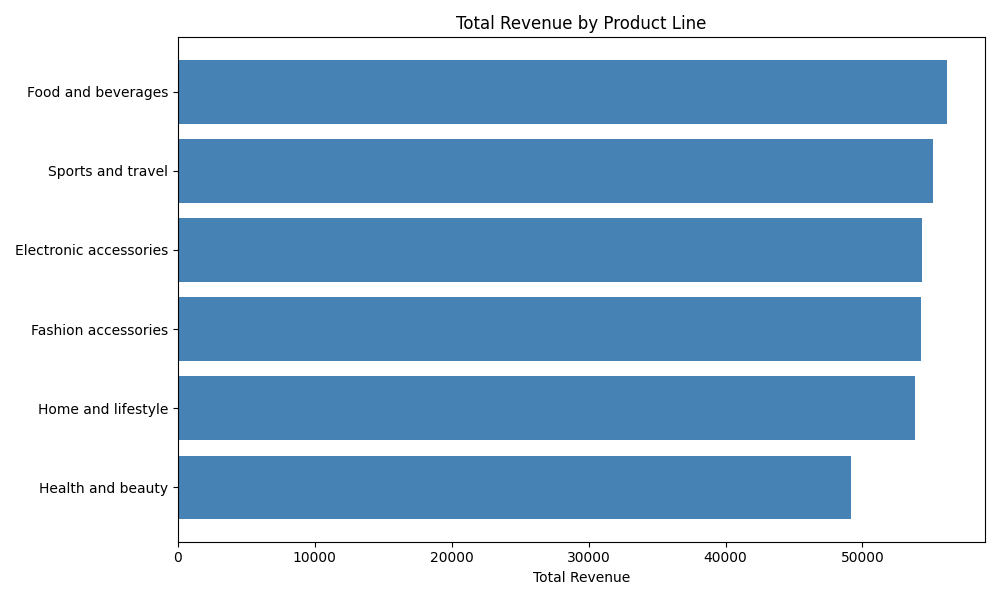

In [63]:
#9
response = my_agent.chat("Plot a bar chart of total revenue by product_line.")
display(Image(response.value))

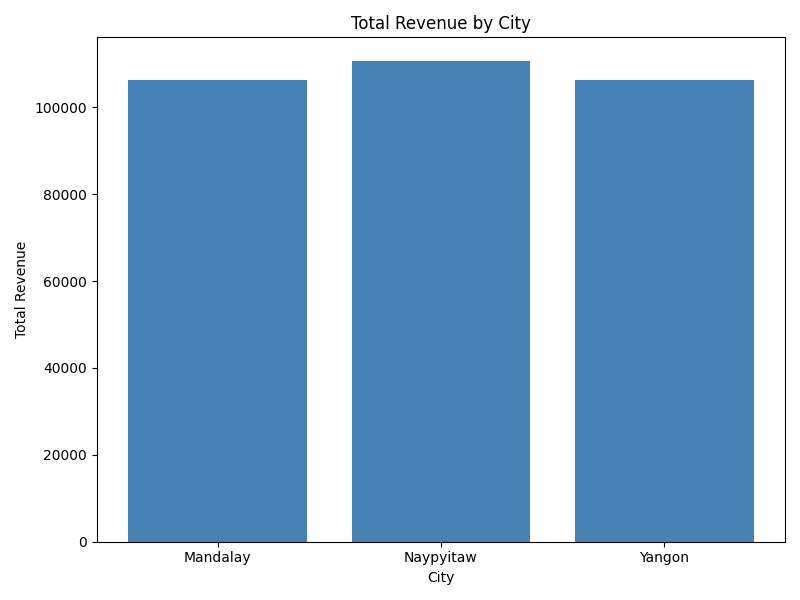

In [57]:
#10
response = my_agent.chat("Compare total revenue across the three cities in a bar chart.")
display(Image(response.value))

# lets compare the manual vs pandasai code

In [68]:
#1
q1 = df.groupby("product_line")["revenue"].sum().sort_values(ascending=False)
p1=my_agent.chat("Which product_line has the highest total revenue? Give the name and the total.")

print("Manual code:\n",q1)
print("\npandas ai code:\n",p1)

Manual code:
 product_line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: revenue, dtype: float64

pandas ai code:
 The product line with the highest total revenue is Food and beverages with a total of 56144.84.


#### When comparing the results, the manual Python code displays the total revenue for all product lines, whereas PandasAI returns only the highest revenue value. Therefore, I consider manual Python coding more effective because it provides a complete overview of the results.

In [70]:
#2
q2 =df.groupby("customer_type")["revenue"].mean().round(2)
p2=my_agent.chat("What is the average revenue per invoice for each customer_type?")

print("Manual code:\n",q2)
print("\npandas ai code:\n",p2)

Manual code:
 customer_type
Member    327.79
Normal    318.12
Name: revenue, dtype: float64

pandas ai code:
   customer_type  avg_revenue_per_invoice
0        Member               327.791305
1        Normal               318.122856


#### In the customer type analysis, manual Python code allows us to round off values to two decimal places, whereas PandasAI does not provide the same control. However, both produce accurate values, with manual Python offering better formatting flexibility.

In [71]:
#3
q3 = df.groupby("branch")["revenue"].sum().sort_values(ascending=False).round(2)
p3=my_agent.chat("Rank the branches by total revenue, highest first, with the totals.")

print("Manual code:\n",q3)
print("\npandas ai code:\n",p3)

Manual code:
 branch
C    110568.71
A    106200.37
B    106197.67
Name: revenue, dtype: float64

pandas ai code:
   branch  total_revenue
0      C    110568.7065
1      A    106200.3705
2      B    106197.6720


#### For branch-wise analysis, both manual Python code and PandasAI produce the same results with similar formatting flexibility. However, I found PandasAI faster and more convenient than writing the code manually.

## The issue I faced was related to the PandasAI installation. With my mentor's guidance, I downgraded Python to version 3.11, as he suggested, and successfully resolved the installation issue. PandasAI is now working fine.